In [1]:
import sys
from pathlib import Path

mother_dir = Path.cwd().parent

if str(mother_dir) not in sys.path:
    sys.path.append(str(mother_dir))

In [2]:
from torchvision import datasets
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision.io import decode_image
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torchvision.transforms import v2
from PIL import Image
from collections import Counter
from matplotlib.colors import hsv_to_rgb

In [5]:
def load_food101(
    root: str = "../data/asm2",
    split: str = "train",
    test_size: float | None = 0.1,
    random_state: int = 42,
    transform=None,
    duplicate_check: bool = False,
    duplicate_csv: str = "food101_data_leakage_pairs.csv",
):
    Path(root).mkdir(parents=True, exist_ok=True)

    full_dataset = datasets.Food101(
        root=root,
        split=split,
        download=True,
        transform=transform,
    )

    # Original dataset indices
    valid_indices = list(range(len(full_dataset)))

    # Remove duplicates from training data only
    if duplicate_check and split == "train":
        duplicate_df = pd.read_csv(duplicate_csv)

        # Only remove the first image (always in the train set) from each duplicate pair
        duplicate_indices = set(
            duplicate_df["index_1"].astype(int)
        )

        # Validate against original Food101 indices
        invalid_indices = {
            i for i in duplicate_indices
            if i < 0 or i >= len(full_dataset)
        }

        if invalid_indices:
            raise ValueError(
                f"Invalid duplicate indices: {sorted(invalid_indices)}"
            )

        valid_indices = [
            i for i in valid_indices
            if i not in duplicate_indices
        ]

        print(f"Removed {len(duplicate_indices)} duplicate images.")
        print(f"Remaining training images: {len(valid_indices)}")

    # Return the complete dataset (or filtered train subset)
    if split != "train" or test_size is None:
        return Subset(full_dataset, valid_indices), None

    # Labels corresponding to remaining indices
    valid_labels = [
        full_dataset._labels[i]
        for i in valid_indices
    ]

    train_idx, val_idx = train_test_split(
        valid_indices,
        test_size=test_size,
        stratify=valid_labels,
        random_state=random_state,
    )

    train_dataset = Subset(full_dataset, train_idx)
    val_dataset = Subset(full_dataset, val_idx)

    return train_dataset, val_dataset

In [6]:
train_dataset, val_dataset = load_food101(split="train")
train_clean_dataset, _ = load_food101(split="train", duplicate_check=True)

Removed 162 duplicate images.
Remaining training images: 75588


In [ ]:
sizes = []

for idx in train_dataset.indices:
    path = train_dataset.dataset._image_files[idx]

    with Image.open(path) as img:
        sizes.append(img.size)
        

print("Unique sizes:", len(set(sizes)))
print("Most common sizes:", Counter(sizes).most_common(10))
print("Min width:", min(w for w, h in sizes))
print("Max width:", max(w for w, h in sizes))
print("Min height:", min(h for w, h in sizes))
print("Max height:", max(h for w, h in sizes))

In [8]:
train_tensor_clean_dataset, val_tensor_dataset = load_food101(
    split="train", 
    duplicate_check=True, 
    transform=v2.Compose([
        v2.Resize((512, 512)),
        v2.ToTensor()
    ])
)

d:\VKhang\Study\HK261\DL\CO3133-DeepLearning\.venv-1\Lib\site-packages\torchvision\transforms\v2\_deprecated.py:42: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.Output is equivalent up to float precision.
  warnings.warn(


Removed 162 duplicate images.
Remaining training images: 75588


In [9]:
def plot_image_from_dataset(dataset, idx = None, count = 5):
    idx = np.random.choice(len(dataset), count, replace=False) if idx is None else idx
    for i in range(count):
        image, label = dataset[idx[i]]
        plt.subplot(1, count, i + 1)
        plt.imshow(image.permute(1, 2, 0))
        plt.title(f"Index: {idx[i]}")
        plt.axis("off")
    plt.tight_layout()
    plt.show()

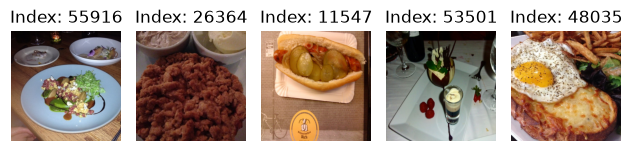

In [10]:
plot_image_from_dataset(train_tensor_clean_dataset, count=5)

Background noises: contains non-food elements in the background, some images do not have food as the central component

In [11]:
# Class distribution
from matplotlib import image


def plot_class_distribution(dataset, title="Class Distribution"):
    labels = [dataset.dataset._labels[idx] for idx in dataset.indices]
    label_counts = Counter(labels)
    classes, counts = zip(*label_counts.items())
    
    plt.figure(figsize=(12, 6))
    plt.bar(classes, counts)
    plt.xticks(rotation=90)
    plt.title(title)
    plt.xlabel("Classes")
    plt.ylabel("Number of Samples")
    plt.show()
    print(label_counts)

# RGB channel distribution
def plot_rgb_distribution(dataset, title="RGB Channel Distribution"):
    hist = np.zeros((3, 256), dtype=np.int64)

    for image, _ in dataset:
        if isinstance(image, torch.Tensor):
            image = (image * 255).round().clamp(0, 255).to(torch.uint8)
            image = image.permute(1, 2, 0).numpy()
        else:
            image = np.asarray(image.convert("RGB"))

        pixels = image.reshape(-1, 3)

        for c in range(3):
            hist[c] += np.bincount(pixels[:, c], minlength=256)

    plt.figure(figsize=(12, 5))

    for c, color in enumerate(["red", "green", "blue"]):
        plt.plot(
            np.arange(256),
            hist[c] / hist[c].sum(),
            color=color,
            label=color.upper()
        )

    plt.xlabel("Pixel intensity")
    plt.ylabel("Relative frequency")
    plt.title(title)
    plt.legend()
    plt.show()

    return hist

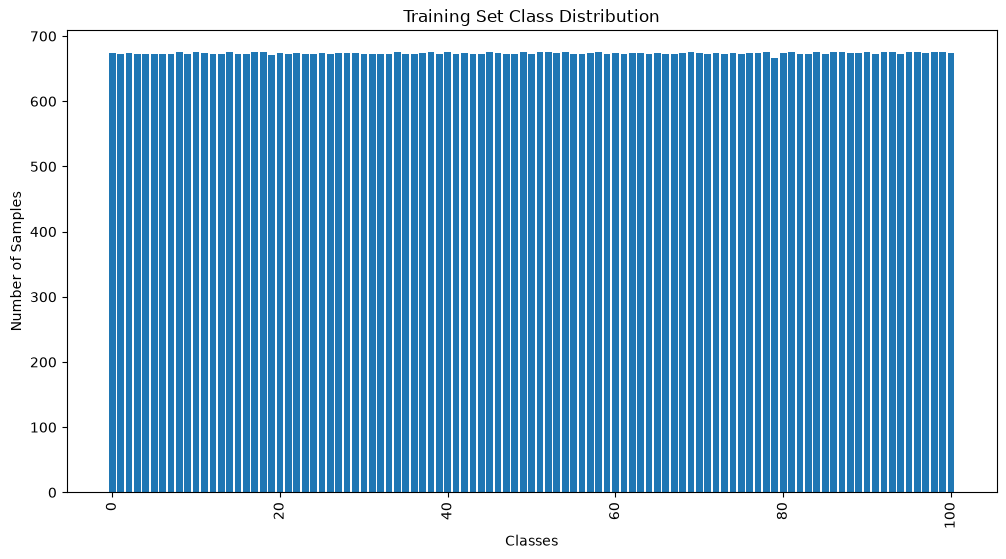

Counter({96: 675, 10: 675, 95: 675, 93: 675, 92: 675, 84: 675, 98: 675, 87: 675, 86: 675, 45: 675, 49: 675, 8: 675, 38: 675, 34: 675, 14: 675, 17: 675, 51: 675, 69: 675, 78: 675, 18: 675, 54: 675, 52: 675, 90: 675, 99: 675, 58: 675, 40: 675, 81: 675, 2: 674, 77: 674, 0: 674, 25: 674, 89: 674, 11: 674, 100: 674, 27: 674, 63: 674, 72: 674, 62: 674, 53: 674, 57: 674, 46: 674, 97: 674, 65: 674, 28: 674, 37: 674, 70: 674, 22: 674, 76: 674, 74: 674, 80: 674, 20: 674, 88: 674, 42: 674, 60: 674, 68: 674, 29: 674, 94: 673, 9: 673, 48: 673, 15: 673, 56: 673, 21: 673, 73: 673, 6: 673, 24: 673, 44: 673, 85: 673, 36: 673, 67: 673, 3: 673, 32: 673, 66: 673, 26: 673, 7: 673, 61: 673, 13: 673, 4: 673, 23: 673, 16: 673, 64: 673, 12: 673, 35: 672, 50: 672, 47: 672, 33: 672, 41: 672, 75: 672, 30: 672, 83: 672, 91: 672, 55: 672, 31: 672, 5: 672, 39: 672, 43: 672, 1: 672, 71: 672, 59: 672, 82: 672, 19: 671, 79: 666})


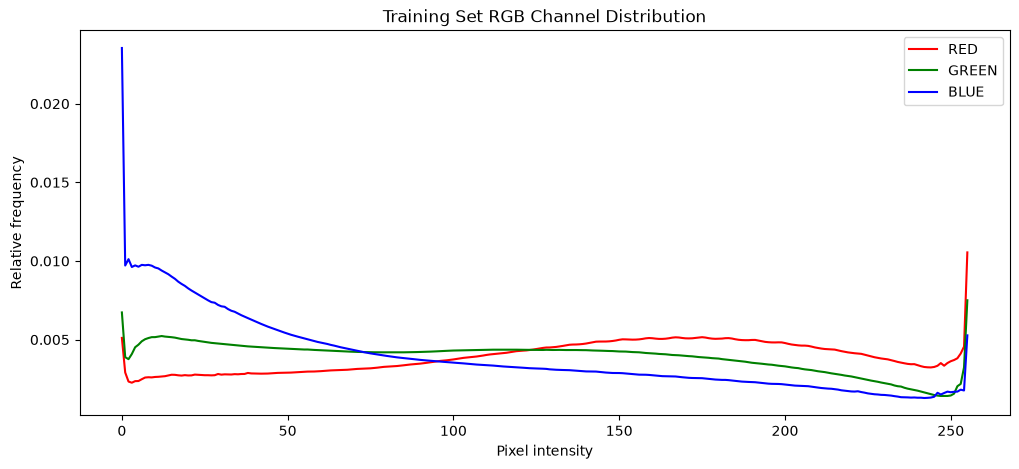

RGB mean: [0.54501185 0.44361367 0.34368521]
RGB std: [0.27204728 0.27460895 0.27929759]


In [12]:
plot_class_distribution(train_tensor_clean_dataset, title="Training Set Class Distribution")
hist = plot_rgb_distribution(train_tensor_clean_dataset, title="Training Set RGB Channel Distribution")
values = np.arange(256, dtype=np.float64)
prob = hist / hist.sum(axis=1, keepdims=True)

mean = (prob * values).sum(axis=1) / 255
std = np.sqrt(
    (prob * (values - (mean * 255)[:, None])**2).sum(axis=1)
) / 255

print("RGB mean:", mean)
print("RGB std:", std)

- Class distributed fairly, even with duplicates removed 
- Red channel dominates (higher frequency for higher pixel intensity) --> warm colors (red, orange, yellow,...) appear frequently.
- High frequency of Blue = 0

In [13]:
def plot_hsv_distribution(dataset, min_hue_saturation=0.1, clean_duplicates=False):
    hist = np.zeros((3, 256), dtype=np.int64)

    for image, _ in dataset:
        hsv = np.asarray(image.convert("HSV"))

        hue = hsv[:, :, 0]
        saturation = hsv[:, :, 1]
        value = hsv[:, :, 2]

        # Filter low-saturation pixels for Hue
        mask = saturation > min_hue_saturation * 255

        hist[0] += np.bincount(
            hue[mask], minlength=256
        )
        hist[1] += np.bincount(
            saturation.ravel(), minlength=256
        )
        hist[2] += np.bincount(
            value.ravel(), minlength=256
        )

    # Normalize to relative frequency
    prob = hist / np.maximum(
        hist.sum(axis=1, keepdims=True), 1
    )

    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

    # ---- Hue: 0 to 360 degrees ----
    hue_degrees = np.arange(256) * 360 / 256

    hue_colors = hsv_to_rgb(
        np.column_stack([
            np.arange(256) / 256,
            np.ones(256),
            np.ones(256)
        ])
    )

    axes[0].bar(
        hue_degrees,
        prob[0],
        width=360 / 256,
        align="edge",
        color=hue_colors,
        edgecolor="none"
    )
    axes[0].set_xlim(0, 360)
    axes[0].set_xticks(np.arange(0, 361, 60))
    axes[0].set_xlabel("Hue (degrees)")
    axes[0].set_title(
        f"Hue Distribution (S > {min_hue_saturation})"
    )

    # ---- Saturation & Value: 0 to 1 ----
    normalized_values = np.arange(256) / 255

    for c, color, name in [
        (1, "green", "Saturation"),
        (2, "orange", "Value")
    ]:
        axes[c].plot(
            normalized_values,
            prob[c],
            color=color
        )
        axes[c].set_xlim(0, 1)
        axes[c].set_xticks(np.linspace(0, 1, 6))
        axes[c].set_xlabel(f"{name} (0–1)")
        axes[c].set_title(f"{name} Distribution")

    for ax in axes:
        ax.set_ylabel("Relative frequency")
        ax.grid(alpha=0.2)

    plt.suptitle("Food101 Training Set HSV Distribution (512x512, Cleaned Duplicates)" if clean_duplicates else "Food101 Training Set HSV Distribution (512x512)")
    plt.tight_layout()
    plt.show()

    return hist

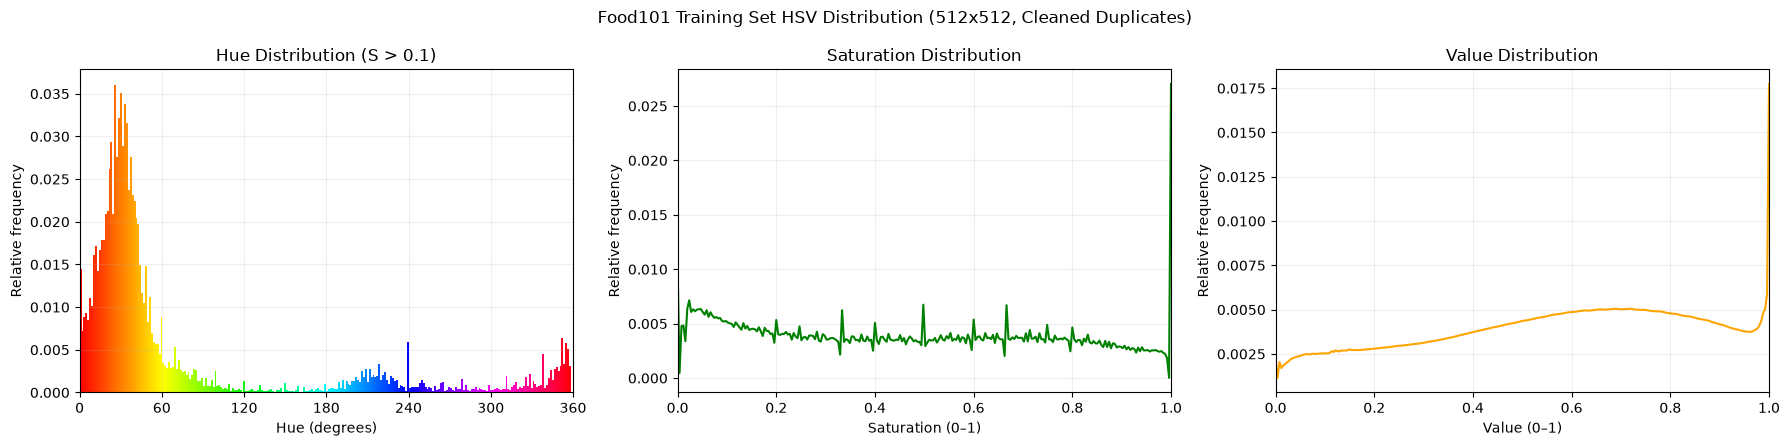

In [15]:
hsv_hist_clean = plot_hsv_distribution(train_clean_dataset, clean_duplicates=True)

- Warm colors dominate, many saturated and bright pixels but they do not dominate, overall even distribution, further color augmentation may be redundant.